
César Santiago Esparza Guzmán         2184325

Rodríguez Chaires Raúl Cristóbal      2201389

Jorge Daniel García Ortiz             2189190

Nicolás García Pinto                  2188223

David Lazos Ramírez                   2276044

Jesús Rodrigo Alemán Marines          2153639



La lógica empleada para esta primer celda se basa en la declaración de las librerias que utilizaremos para el analisis de estos datos asi como el URL del Dataframe que contiene los datos que analizaremos de los pacientes y el cual importamos con la librería "pandas" y de este modo mostramos las primeras 5 filas del dataframe

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split, GridSearchCV

# URL pública del dataset de Diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


En esta segunda celda se emplean las funciones .info y .describe en el dataframe declarado como df para poder obtener un resumen estadistico detallado del Dataframe

In [25]:
#Resumen estadistico del DataFrame
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


En la siguiente celda se usa la función print y .dtypes para mostrar un resumen de las columnas del dataframe con sus tipo de dato

In [26]:
#Analizar el tipo de datos del DataFrame
print(df.dtypes)

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


En esta celda se emplea la función .isnull.sum con el objetivo de encontrar los valores nulos en cada columna y sumarlos

In [27]:
#Detección de valores nulos o anomalías
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


A continuación se muestra una lista con 5 de las columnas que podrían presentar ceros en sus columnas, de este modo se realiza un comparación y una suma para hallar la cantidad de ceros por columna, también se calcula su porcentaje de En esta celda revisamos la calidad de la información aplicando estos 4 pasos


1. Identificamos ceros sospechosos: Busqué valores en 0 que son imposibles en la vida real como tener 0 de glucosa o presión para saber exactamente cuántos datos reales nos hacen falta.
2. Calculamos el porcentaje de falta: Medimos qué tan grande es el vacío de información en cada una de las columnas.
3. Analizamos el balance de los datos: Contamos cuántos pacientes sanos y cuántos con diabetes tenemos en el grupo para conocer el equilibrio de la muestra.
4. Buscamos duplicados: Confirmamos si había registros repetidos para evitar ingresar personas duplicadas por error.


In [28]:
#Anomalias en columnas con 0
columnas_con_ceros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("\nCantidad de ceros por columna (posibles valores faltantes ocultos):")
print((df[columnas_con_ceros] == 0).sum())

print("\nPorcentaje de ceros por columna:")
print(((df[columnas_con_ceros] == 0).mean() * 100).round(2))
print("\nDistribución de Outcome:")
print(df['Outcome'].value_counts())
print(df['Outcome'].value_counts(normalize=True).round(3))
print("\nFilas duplicadas:", df.duplicated().sum())


Cantidad de ceros por columna (posibles valores faltantes ocultos):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Porcentaje de ceros por columna:
Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64

Distribución de Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Filas duplicadas: 0


Separamos a los pacientes con diabetes y que no la presentan usando la columna Outcome debendiendo de si su valor es 1 o 0 y creamos el grafico de dispersión con sus respectivos tiulos, leyenda, colores y puntos usando las columnas de Glucose y BMI para establecer una relación

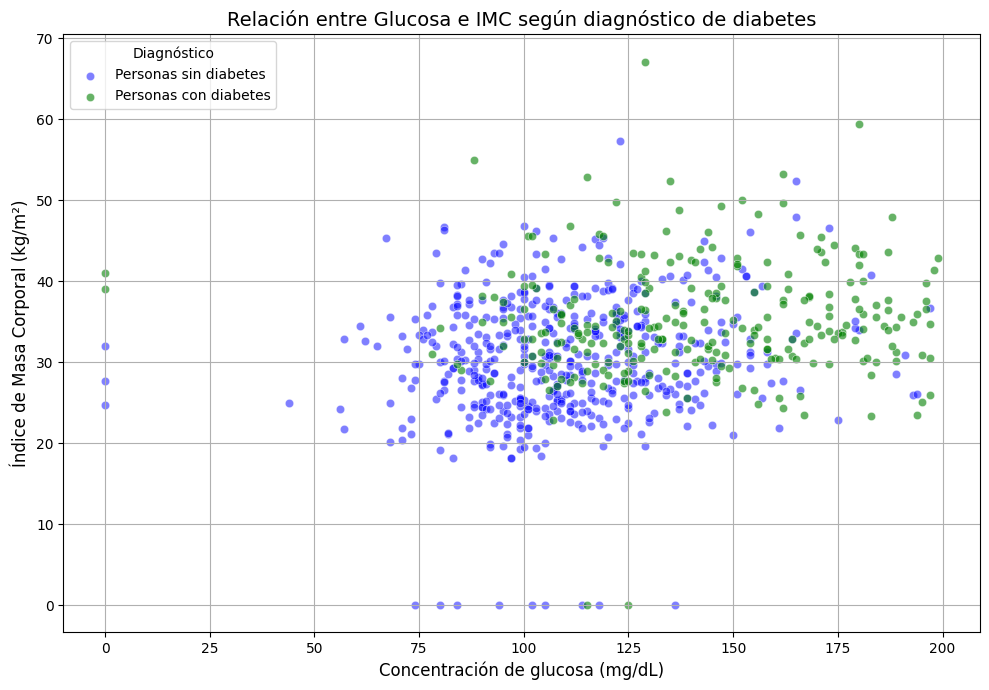

In [29]:
# Separar pacientes según el resultado
sin_diabetes = df[df['Outcome'] == 0]
con_diabetes = df[df['Outcome'] == 1]

plt.figure(figsize=(10, 7))

plt.scatter(sin_diabetes['Glucose'], sin_diabetes['BMI'], c='blue', alpha=0.5, edgecolors='white', linewidths=0.5, label='Personas sin diabetes')
plt.scatter(con_diabetes['Glucose'], con_diabetes['BMI'], c='green', alpha=0.6, edgecolors='white', linewidths=0.5, label='Personas con diabetes' )

plt.title('Relación entre Glucosa e IMC según diagnóstico de diabetes', fontsize=14)
plt.xlabel('Concentración de glucosa (mg/dL)', fontsize=12)
plt.ylabel('Índice de Masa Corporal (kg/m²)', fontsize=12)
plt.grid(True)
plt.legend(title='Diagnóstico', loc='upper left')

plt.tight_layout()
plt.show()

En esta celda preparamos los datos para eliminar los ceros presenten en algunas columnas copiando el dataframe original y creando un dataframe limpio remplazando los ceros en las columnas con ceros

In [30]:
#Reeplazar los ceros
columnas_con_ceros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df_limpio = df.copy()


df_limpio[columnas_con_ceros] = df_limpio[columnas_con_ceros].replace(0, np.nan)

print("Nulos reales detectados por columna:")
print(df_limpio[columnas_con_ceros].isnull().sum())

Nulos reales detectados por columna:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


El siguiente paso de nuestro codigo es calcular la mediana de esas 5 columnas para de este modo reemplazar las filas con 0 con esas medianas previamente calculadas

In [31]:
# 2. Calculo de las medianas
medianas = df_limpio[columnas_con_ceros].median()
print("\nMedianas utilizadas:")
print(medianas)

df_limpio[columnas_con_ceros] = df_limpio[columnas_con_ceros].fillna(medianas)

print("\nNulos despues de la mediana:")
print(df_limpio.isnull().sum())


Medianas utilizadas:
Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64

Nulos despues de la mediana:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


En esta celda nos encargamos de identificar y filtrar los datos exageradamente altos o fuera de lo común en la insulina:

Identificamos el rango normal: Usamos una regla estadística llamada rango intercuartílico para ver dónde se concentra la gran mayoría de nuestros pacientes.

Calculamos un límite máximo permitido basado en el comportamiento normal de la insulina.

Eliminamos del grupo a las personas con valores de insulina exagerados que podrían distorsionar o confundir a nuestro modelo de predicción, quedándonos solo con los datos más confiables.


In [32]:

# 3. Outliers en Insulin con IQR (1.5 * IQR)
Q1 = np.percentile(df_limpio['Insulin'], 25)
Q3 = np.percentile(df_limpio['Insulin'], 75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"\nQ1={Q1:.2f}  Q3={Q3:.2f}  IQR={IQR:.2f}")
print(f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}]")

filas_antes = len(df_limpio)
df_limpio = df_limpio[
    (df_limpio['Insulin'] >= limite_inferior) &
    (df_limpio['Insulin'] <= limite_superior)
].reset_index(drop=True)

print(f"\nFilas antes: {filas_antes} | después: {len(df_limpio)} "
      f"| eliminadas: {filas_antes - len(df_limpio)}")


Q1=121.50  Q3=127.25  IQR=5.75
Límites: [112.88, 135.88]

Filas antes: 768 | después: 422 | eliminadas: 346


In [33]:
df_limpio = df.copy()
df_limpio[columnas_con_ceros] = df_limpio[columnas_con_ceros].replace(0, np.nan)

# Límites IQR sobre los valores reales (ignorando NaN)
insulina_real = df_limpio['Insulin'].dropna()
Q1 = np.percentile(insulina_real, 25)
Q3 = np.percentile(insulina_real, 75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Imputación con la mediana
df_limpio[columnas_con_ceros] = df_limpio[columnas_con_ceros].fillna(
    df_limpio[columnas_con_ceros].median()
)

# Filtro con los límites calculados antes de imputar
df_limpio = df_limpio[
    df_limpio['Insulin'].between(limite_inferior, limite_superior)
].reset_index(drop=True)

print(f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print("Filas restantes:", len(df_limpio))

Límites: [-94.38, 360.62]
Filas restantes: 744


Preparamos los datos para el arbol de decisión usando como x las columnas a excepción de la columna Outcome y para Y usamos solo la columna Outcome

In [40]:
# 1. Preparación de los datos
X = df_limpio.drop(columns=['Outcome'])
y = df_limpio['Outcome']

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Forma de X: (744, 8)
Forma de y: (744,)


Empezamos con el entrenamiento del arbol usando un 25% para la prueba y el resto para el entrenamiento

In [35]:
# 2. Partición entrenamiento / prueba (75% - 25%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(f"\nEntrenamiento: {X_train.shape[0]} muestras")
print(f"Prueba:        {X_test.shape[0]} muestras")


Entrenamiento: 558 muestras
Prueba:        186 muestras


Usamos un arbol de decisión que funcionara como un mapa de decisiones simples para aprender si un paciente tiene o no diabetes y realizar una predición eligiendo alguna de estas clases

In [36]:
# 3. Modelado
modelo = DecisionTreeClassifier(random_state=42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

En esta celda medimos la exactitud, calculamos que porcentaje de nuestras predicciones totales fueron correcta, logrando asi un 76% de aciertos, del mismo modo revisamos con que precisión detectamos a los pacientes sanos frente a los que tienen diabetes

In [37]:
# 4. Métricas
print("\nExactitud (Accuracy):", round(accuracy_score(y_test, y_pred), 4))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred,target_names=['Sin diabetes', 'Con diabetes']))


Exactitud (Accuracy): 0.7634

Reporte de clasificación:
              precision    recall  f1-score   support

Sin diabetes       0.86      0.80      0.83       132
Con diabetes       0.58      0.69      0.63        54

    accuracy                           0.76       186
   macro avg       0.72      0.74      0.73       186
weighted avg       0.78      0.76      0.77       186



Finalmente construimos la figura del arbol de decisión con las clase de personas con o sin diabetes, el titulo  y el tamaño

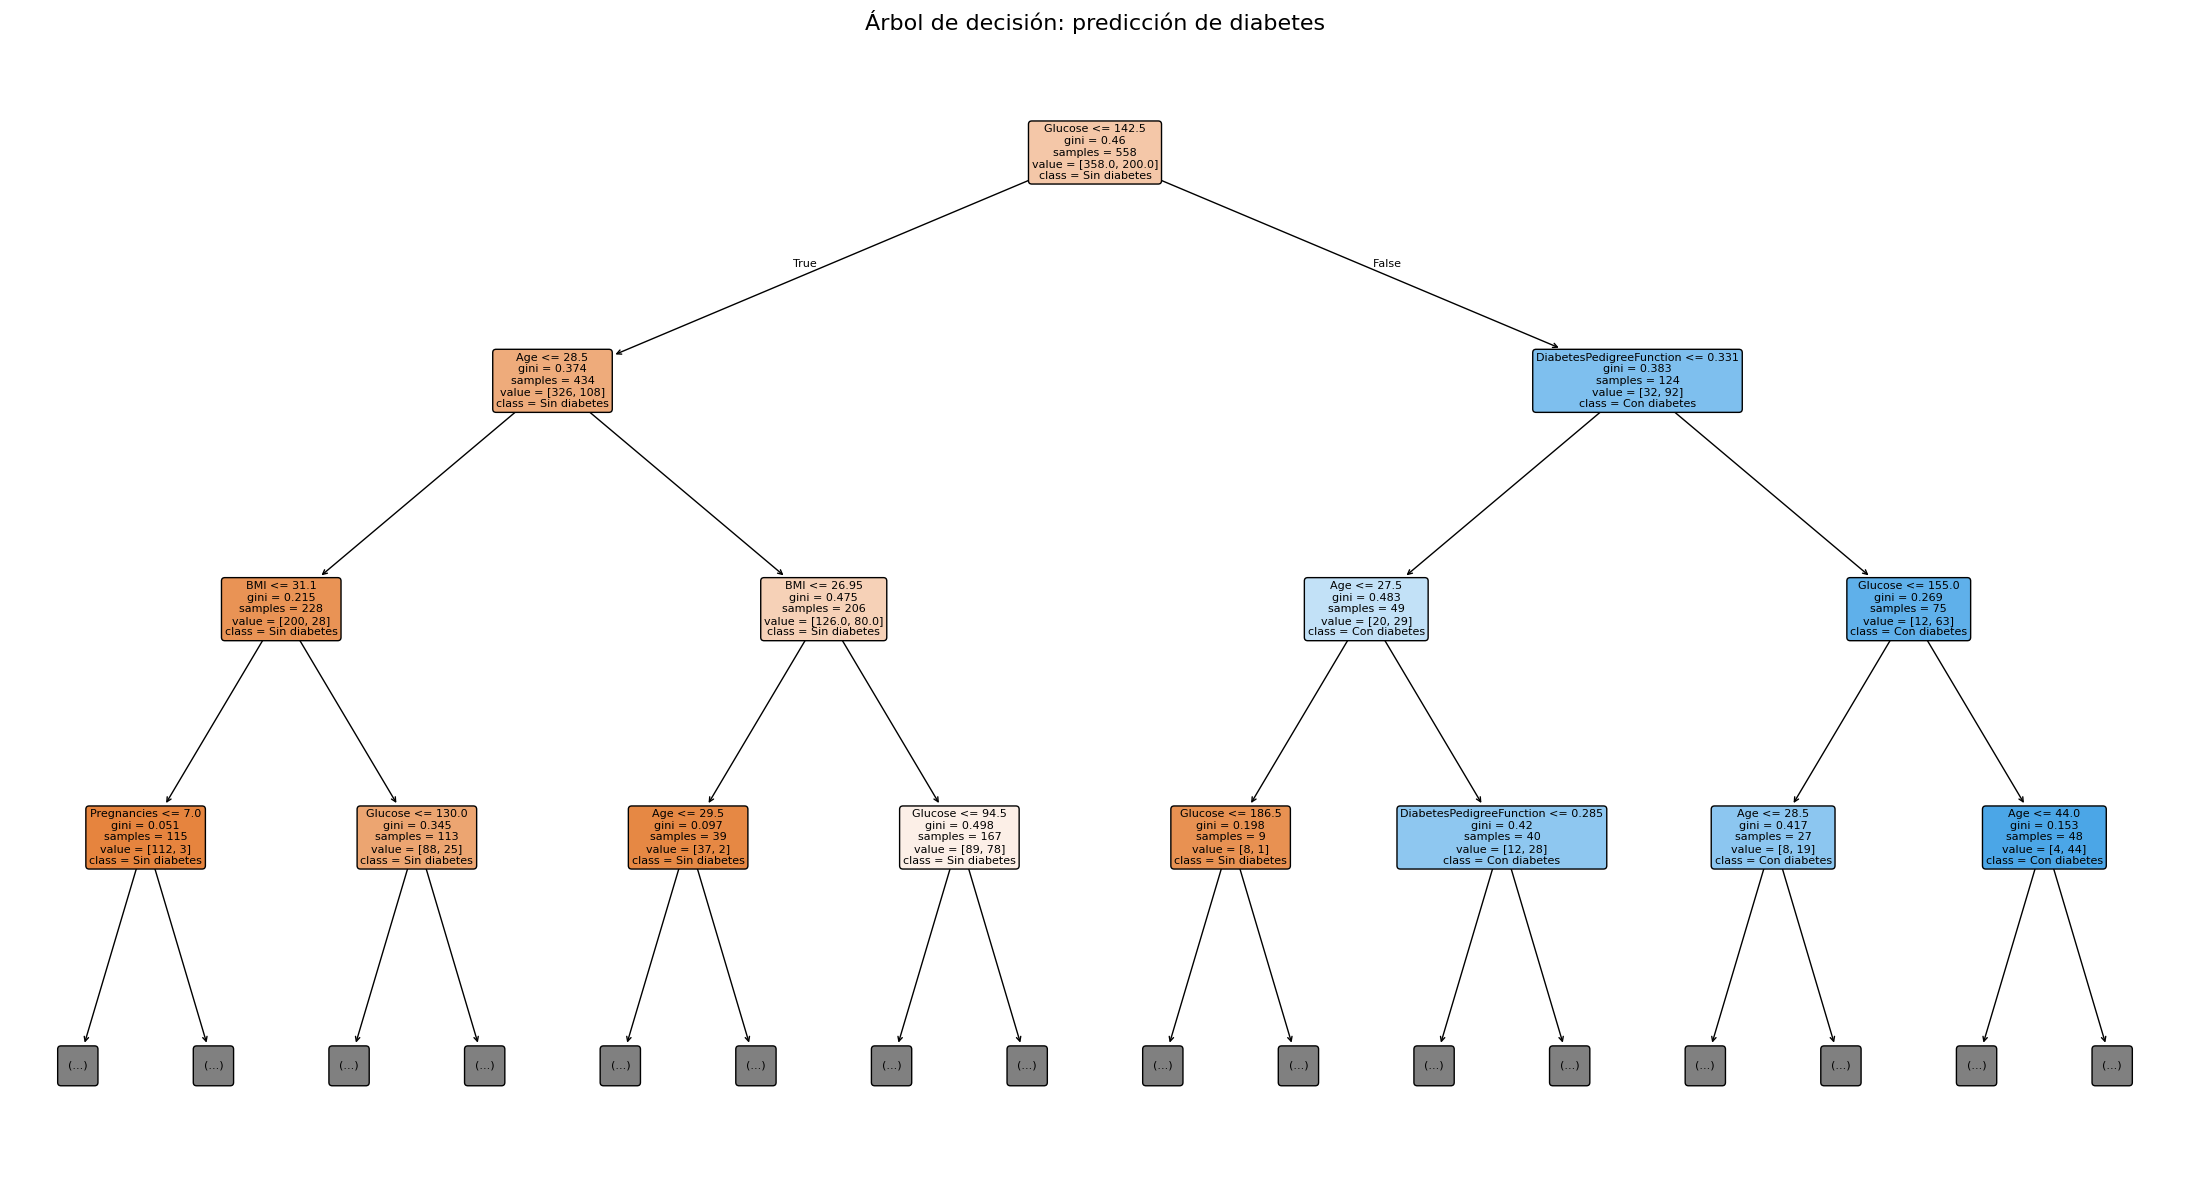

In [38]:
# 5. Visualización del árbol
plt.figure(figsize=(22, 12))
plot_tree( modelo,feature_names=X.columns, class_names=['Sin diabetes', 'Con diabetes'],filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Árbol de decisión: predicción de diabetes', fontsize=16)
plt.tight_layout()
plt.show()